# Credit Card Fraud Detection

An introductory, reproducible study of severe class imbalance. The objective is to identify fraudulent transactions while understanding missed fraud and false alerts.

**How to use:** install `requirements.txt`, place `creditcard.csv` in `data/`, select the project virtual environment as the kernel, then Run All. Start the notebook from the project directory or its `notebooks/` directory. Saved outputs allow reading without running.

This report executes [data_review.py](../data_review.py) and [train_model.py](../train_model.py) as the source of truth. `runpy.run_path` runs a script and returns its variables in a dictionary. This avoids duplicating model code. Every run retrains the same fixed models; it does not search for new settings.

In [1]:
from pathlib import Path
import runpy
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
project_dir = next((p for p in candidates if (p / "train_model.py").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Start this notebook from the project or notebooks directory.")
if not (project_dir / "data" / "creditcard.csv").is_file():
    raise FileNotFoundError("Download creditcard.csv as described in data/README.md.")

# Scripts save figures; the notebook displays those files below.
plt.show = lambda *args, **kwargs: None
print("Project and dataset located.")

Project and dataset located.


## 1. Data inspection and exploratory analysis

**Input:** the original CSV (284,807 rows, 31 columns). **Output:** schema, class counts, missing-value summaries, training-set descriptive statistics, and six plots.

`Class=1` means fraud; `Class=0` means legitimate. `Time` is elapsed seconds, `Amount` is transaction amount, and V1–V28 are anonymized PCA features. Only about 0.173% of records are fraud.

The original exploratory script uses a stratified 60/20/20 split (seed 5) before detailed EDA. Its training set contains 170,884 rows and 295 fraud cases. This is **not** the later deduplicated modeling split.

In [2]:
eda = runpy.run_path(str(project_dir / "data_review.py"))
plt.close("all")

(284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V

          count        mean         std  min   25%    50%      75%       max
Class                                                                       
0      170589.0   87.906355  242.470660  0.0  5.66  22.00   77.050  18910.00
1         295.0  118.621831  259.602833  0.0  1.00   7.57  104.015   2125.87
Class
0    170589
1       295
Name: count, dtype: int64
(165408, 31)


(170589, 31) (295, 31)
count    170884.000000
mean      94930.075654
std       47502.458295
min           0.000000
25%       54272.750000
50%       84905.000000
75%      139473.000000
max      172788.000000
Name: Time, dtype: float64
          count      mean       std        min       25%       50%       75%  \
Class                                                                          
0      170589.0  0.008953  1.922194 -46.855047 -0.919401  0.020666  1.316737   
1         295.0 -4.495117  6.050872 -30.552380 -6.068704 -2.630598 -0.423835   

           max  
Class           
0      2.45493  
1      2.09190  


### Class imbalance and amount distributions

The counts show why predicting every transaction as normal produces high accuracy. Amount is strongly right-skewed. The 0–500 view excludes large amounts only from the plot, not from model training. Normal and fraud histograms are normalized separately within this range; their heights are densities, not fraud probabilities.

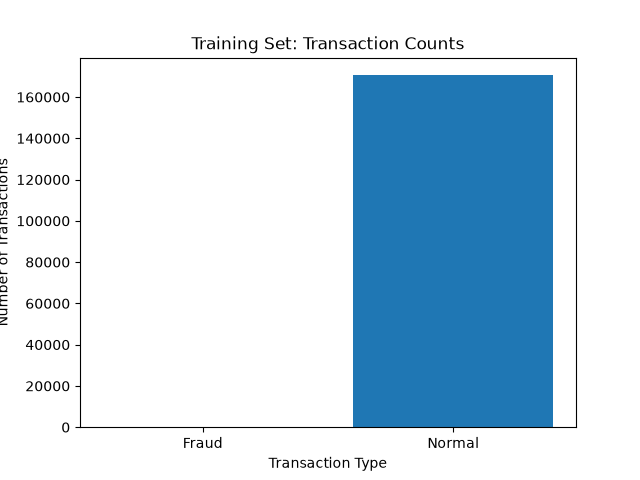

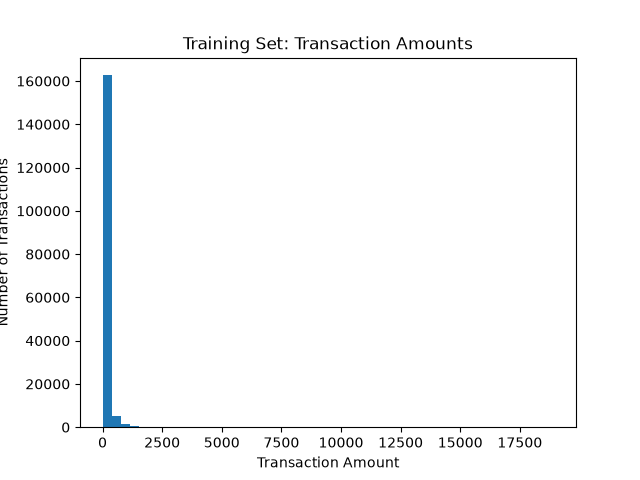

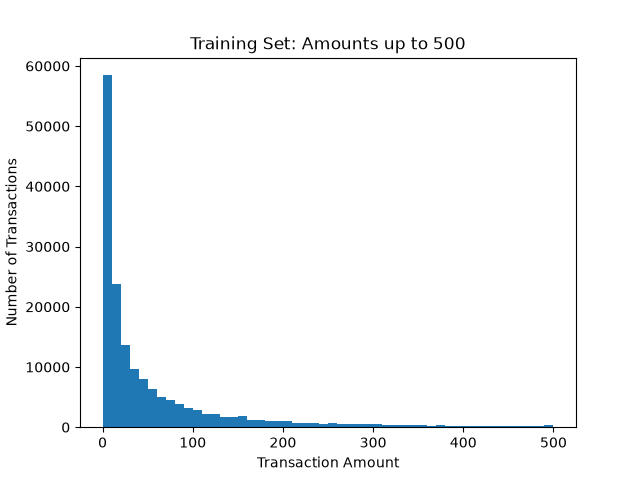

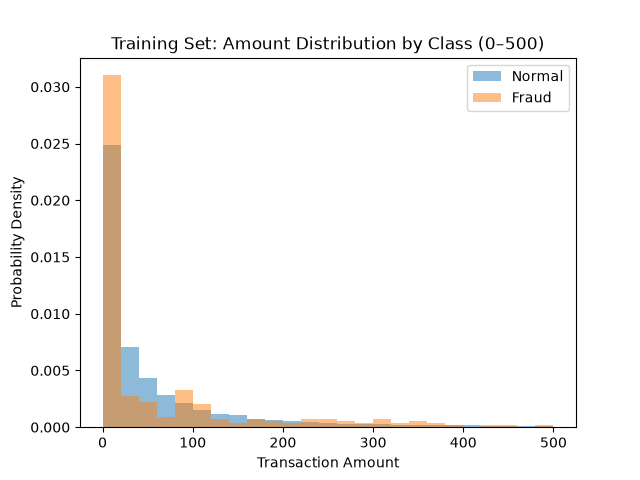

In [3]:
for filename in ["class_distribution.png", "amount_distribution.png",
                 "amount_distribution_under_500.png", "amount_by_class_under_500.png"]:
    display(Image(filename=str(project_dir / "images" / filename)))

### Time and V1

The time plot does not show a clear visual separation; this does not prove time has no predictive value. V1 distributions overlap, although fraud has a lower median. A very negative V1 is not sufficient to establish fraud. These exploratory observations are not causal explanations.

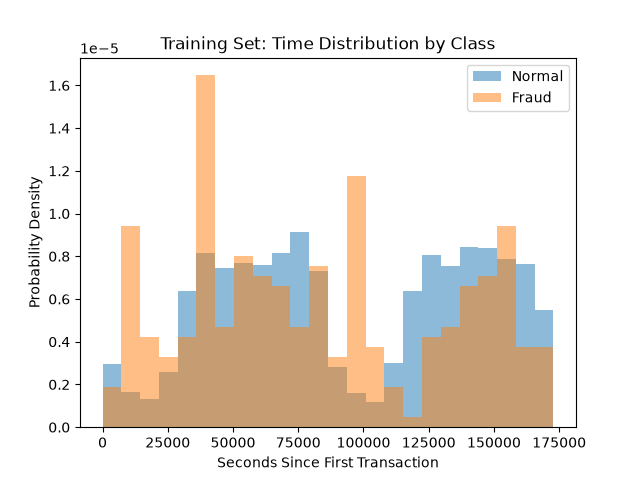

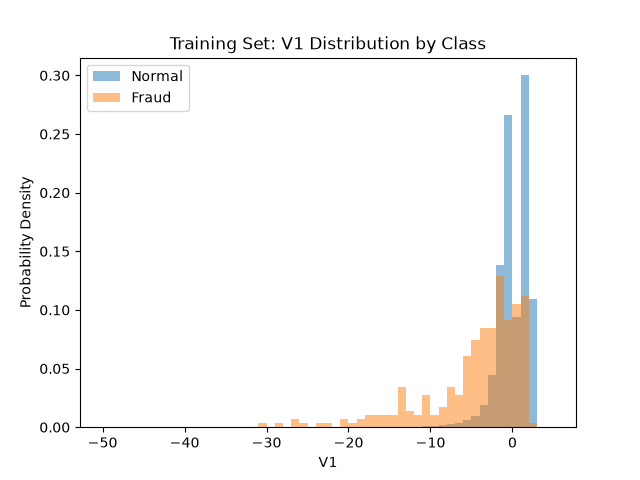

In [4]:
for filename in ["time_by_class.png", "v1_by_class.png"]:
    display(Image(filename=str(project_dir / "images" / filename)))
del eda

## 2. Training and validation

**Input:** the CSV; **output:** trained models, validation scores and curves, a nine-row threshold comparison, and fixed-model test results.

The script removes 1,081 exact duplicate rows in memory, then makes a new stratified 60/20/20 split with seed 5: 170,235 training, 56,745 validation, and 56,746 test rows. Deduplication is a modeling decision, not proof repeated transactions are erroneous. The raw CSV is unchanged. Random splitting and early EDA on a different split limit the independence of this educational evaluation.

Models: always-normal DummyClassifier, ordinary logistic regression, balanced logistic regression, and random forest (100 trees, seed 5). Logistic regressions fit scaling inside a Pipeline using training data only. Random forest uses unscaled features.

The following cell executes the established workflow, including the final evaluation. The forest and 0.3 threshold were selected using validation F1 before test inspection. Re-executing this report verifies reproducibility; do not use the exposed test set to make further choices.

In [5]:
model_run = runpy.run_path(str(project_dir / "train_model.py"))
plt.close("all")

Exact duplicate rows removed: 1081


Exact row overlap between training and validation: 0
Training features and labels: (170235, 30) (170235,)
Validation features and labels: (56745, 30) (56745,)

Baseline — Always predict normal (validation)
Validation transactions: 56745
Accuracy (%): 99.83434663847035
Missed fraud cases: 94

Logistic Regression — Validation, default prediction rule
Predicted fraud alerts: 70
True Positives (TP): 58
Recall: 0.6170212765957447
Precision: 0.8285714285714286
False Positives (FP): 12
False Negatives (FN): 36
True Negatives (TN): 56639
F1: 0.7073170731707318


Average Precision (AP): 0.7073182124101605
ROC-AUC: 0.9720340704958355

Balanced Logistic Regression — Validation, default prediction rule


True Positives (TP): 83
False Positives (FP): 1158
Recall: 0.8829787234042553
Precision: 0.06688154713940371
F1: 0.12434456928838951
Average Precision (AP): 0.6722676142956576
ROC-AUC: 0.9769411217694606

Random Forest — Validation, default prediction rule


True Positives (TP): 73
False Positives (FP): 10
Precision: 0.8795180722891566
Recall: 0.776595744680851
F1: 0.8248587570621468
Average Precision (AP): 0.8253136063422273
ROC-AUC: 0.9504114779668121

Validation model and threshold comparison:
                       Model  Threshold  TP   FP  FN  Precision   Recall       F1
         Logistic Regression        0.2  66   21  28   0.758621 0.702128 0.729282
         Logistic Regression        0.3  61   18  33   0.772152 0.648936 0.705202
         Logistic Regression        0.5  58   12  36   0.828571 0.617021 0.707317
Balanced Logistic Regression        0.2  88 4518   6   0.019106 0.936170 0.037447
Balanced Logistic Regression        0.3  85 2543   9   0.032344 0.904255 0.062454
Balanced Logistic Regression        0.5  83 1158  11   0.066882 0.882979 0.124345
               Random Forest        0.2  79   20  15   0.797980 0.840426 0.818653
               Random Forest        0.3  79   15  15   0.840426 0.840426 0.840426
               Rand

### Default prediction rules: model comparison

Precision asks how many alerts are genuine fraud. Recall asks how much actual fraud is detected. F1 is their harmonic mean. AP summarizes precision as recall changes; ROC-AUC describes ranking across fraud/normal pairs. AP is not interchangeable with trapezoidal PR area. Neither ranking metric establishes calibration.

The always-normal baseline misses all 94 validation fraud cases despite 99.834% accuracy. Balanced logistic regression detects more fraud but produces many false alerts.

In [6]:
validation_metrics = pd.DataFrame([
    {"Model": "Logistic Regression", "Precision": model_run["precision"], "Recall": model_run["recall"], "F1": model_run["F1"], "AP": model_run["ap"], "ROC-AUC": model_run["roc_auc"]},
    {"Model": "Balanced Logistic Regression", "Precision": model_run["balanced_precision"], "Recall": model_run["balanced_recall"], "F1": model_run["balanced_f1"], "AP": model_run["balanced_ap"], "ROC-AUC": model_run["balanced_auc"]},
    {"Model": "Random Forest", "Precision": model_run["forest_precision"], "Recall": model_run["forest_recall"], "F1": model_run["forest_f1"], "AP": model_run["forest_ap"], "ROC-AUC": model_run["forest_auc"]}
])
display(validation_metrics.round(6))

,Model,Precision,Recall,F1,AP,ROC-AUC
0,Logistic Regression,0.828571,0.617021,0.707317,0.707318,0.972034
1,Balanced Logistic Regression,0.066882,0.882979,0.124345,0.672268,0.976941
2,Random Forest,0.879518,0.776596,0.824859,0.825314,0.950411


### Ordinary logistic regression: validation curves

These two figures belong to **ordinary logistic regression on validation data**, not the final forest or test set. A threshold determines a point on the curves; the curves summarize many thresholds.

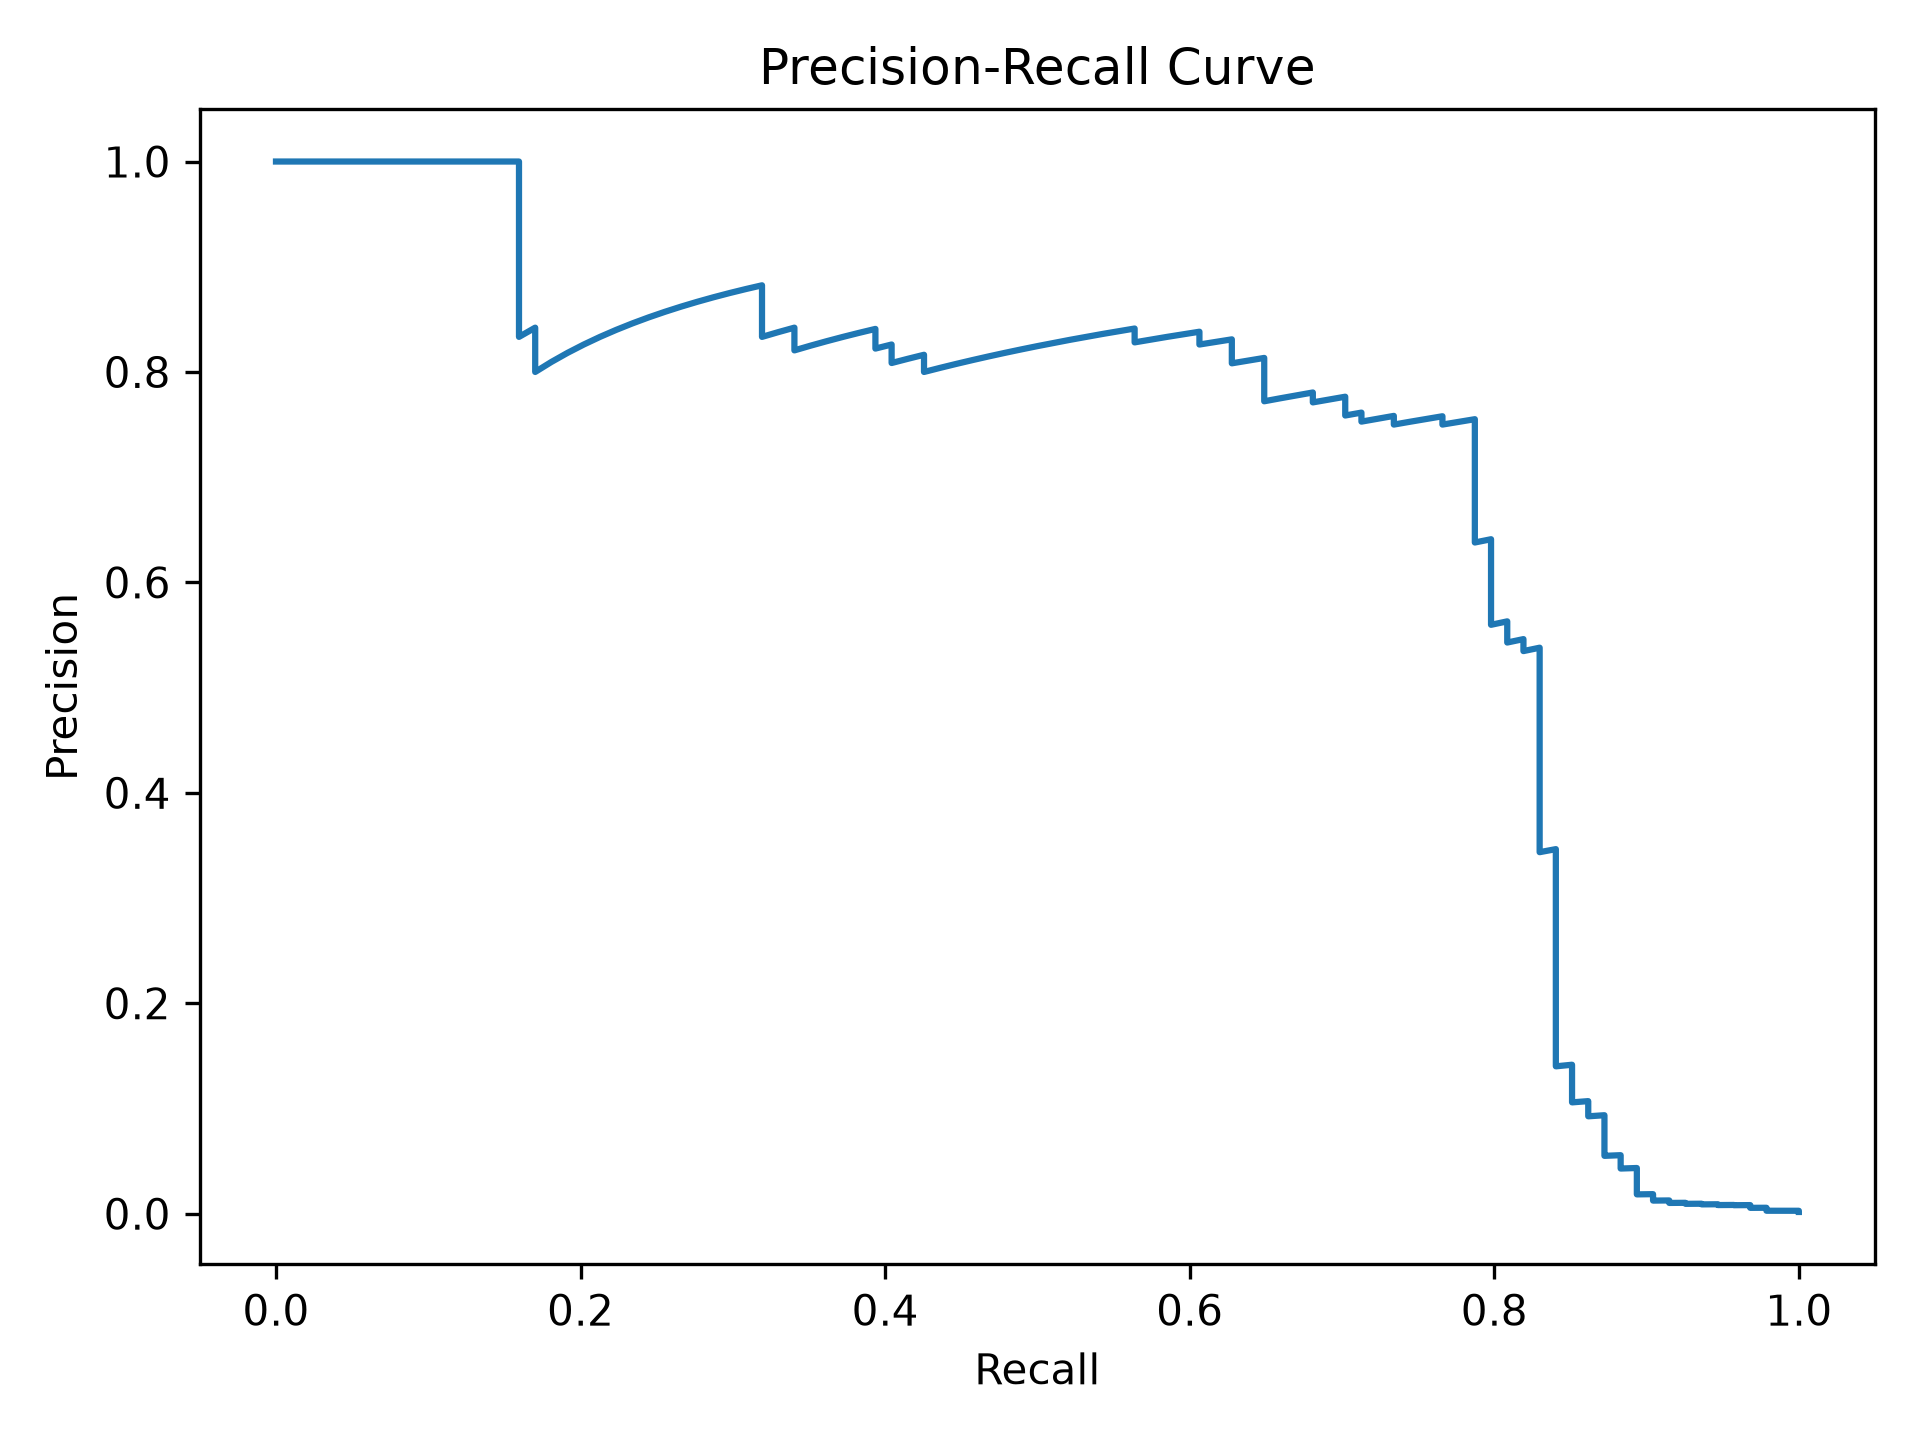

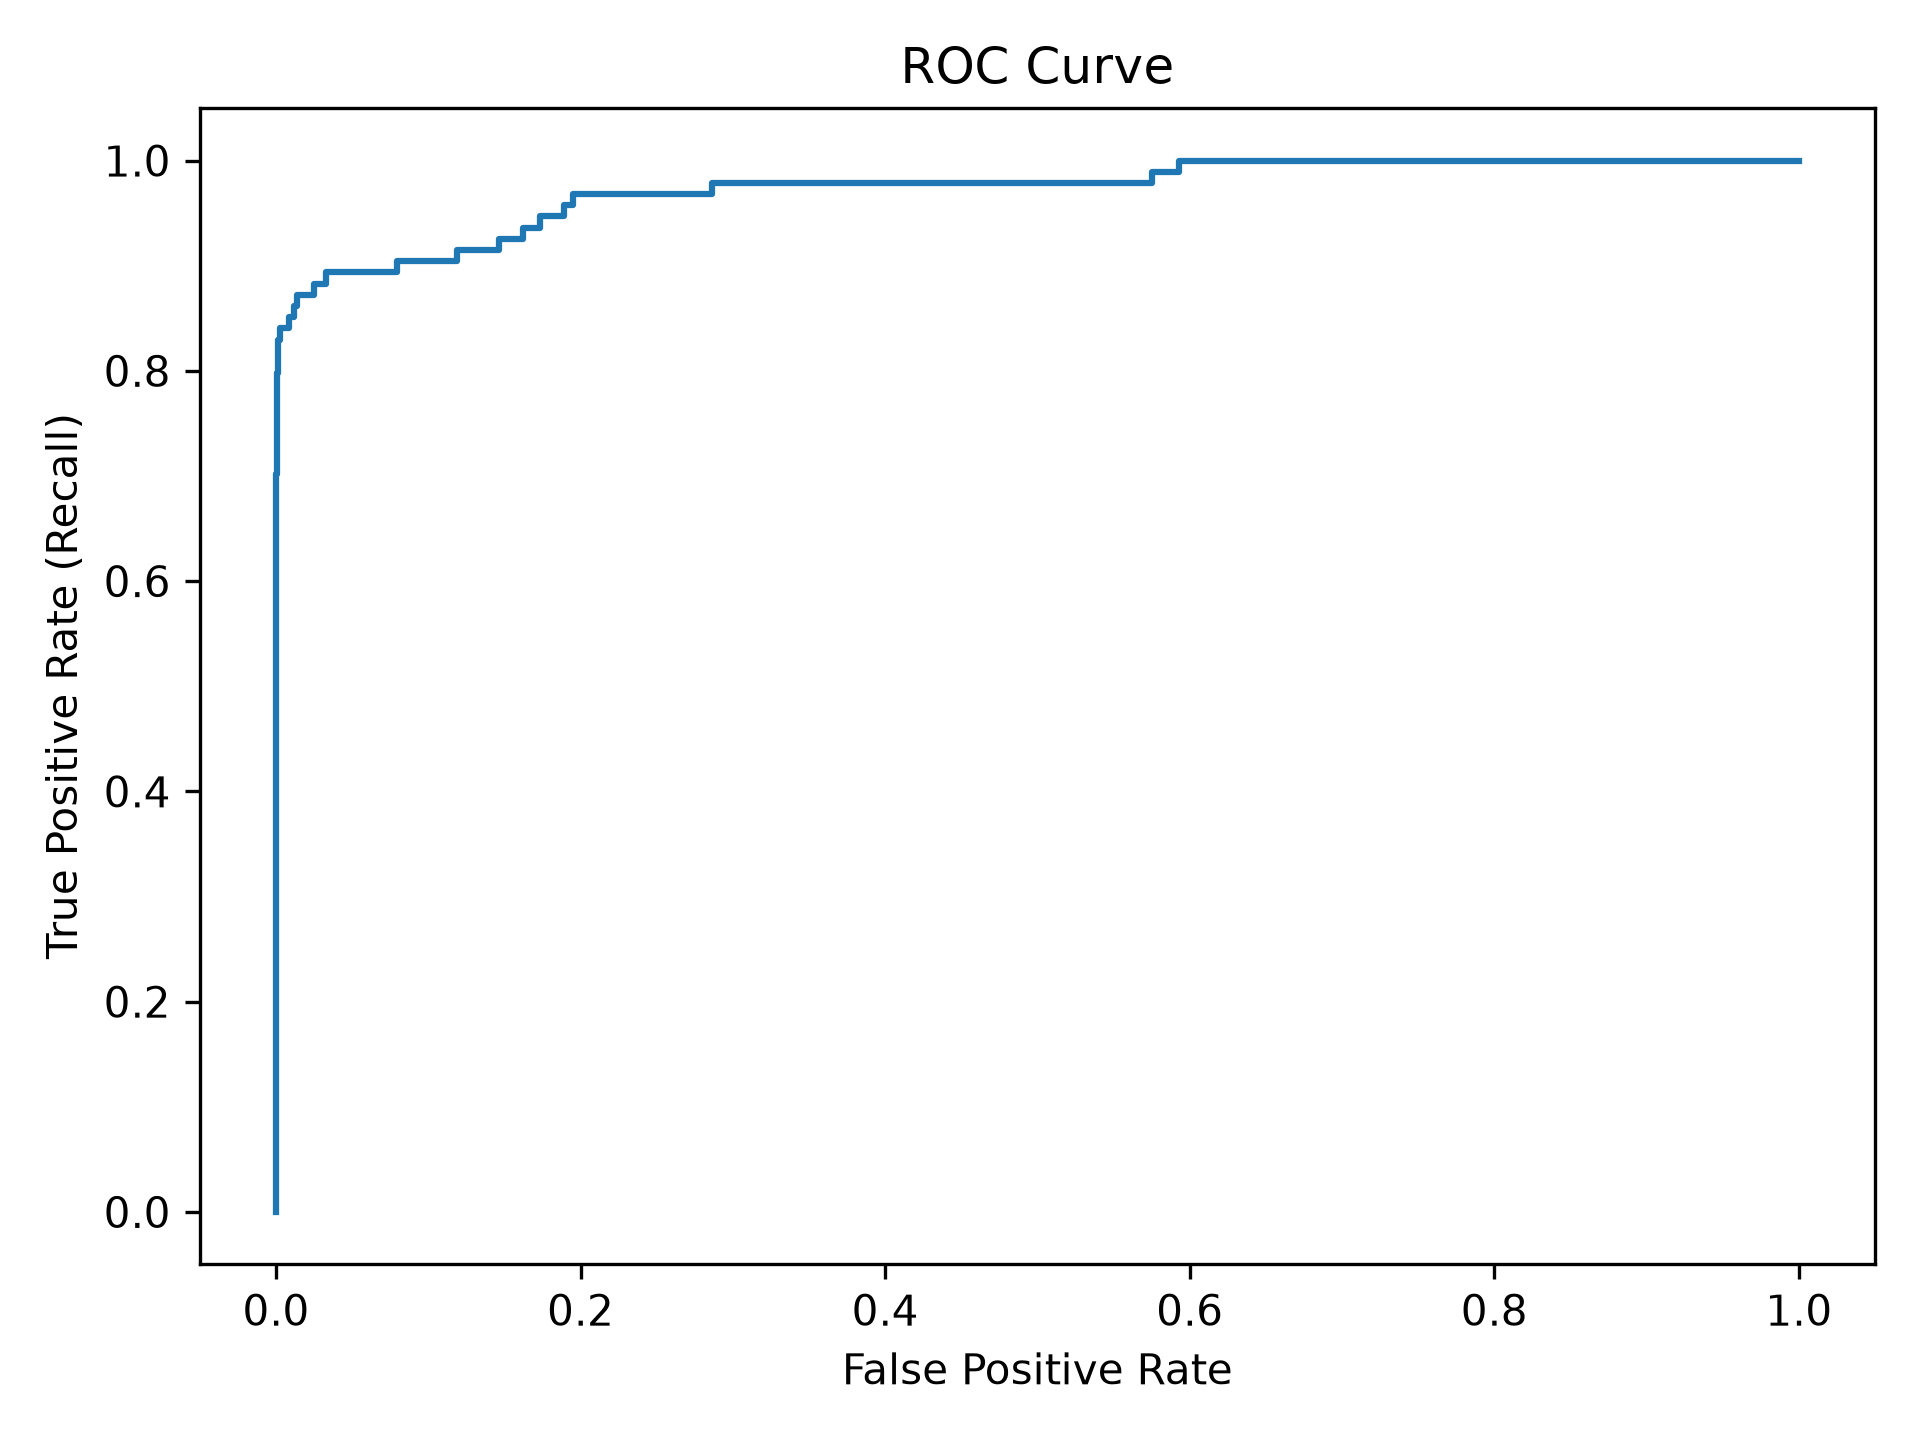

In [7]:
for filename in ["precision_recall_curve.png", "roc_curve.png"]:
    display(Image(filename=str(project_dir / "images" / filename)))

## 3. Threshold selection

Three models × thresholds 0.2, 0.3, 0.5 give nine candidates. A score >= threshold means fraud. Highest validation F1 selects random forest at 0.3. Compared with 0.5, it detects six additional fraud cases for five extra false alerts. At 0.2 it detects no more fraud than 0.3 but adds five false alerts. This selection is specific to this grid and split, not a universal optimum.

In [8]:
display(model_run["comparison_table"].round(6))

,Model,Threshold,TP,FP,FN,Precision,Recall,F1
0,Logistic Regression,0.2,66,21,28,0.758621,0.702128,0.729282
1,Logistic Regression,0.3,61,18,33,0.772152,0.648936,0.705202
2,Logistic Regression,0.5,58,12,36,0.828571,0.617021,0.707317
3,Balanced Logistic Regression,0.2,88,4518,6,0.019106,0.936170,0.037447
4,Balanced Logistic Regression,0.3,85,2543,9,0.032344,0.904255,0.062454
5,Balanced Logistic Regression,0.5,83,1158,11,0.066882,0.882979,0.124345
6,Random Forest,0.2,79,20,15,0.797980,0.840426,0.818653
7,Random Forest,0.3,79,15,15,0.840426,0.840426,0.840426
8,Random Forest,0.5,73,10,21,0.879518,0.776596,0.824859


## 4. Final test results

The already-trained forest was not refitted on training plus validation. On 56,746 test transactions (95 fraud), it produces 82 alerts: 71 true positives and 11 false positives, while missing 24 fraud cases. These test scores are for reporting, not additional model selection.

In [9]:
test_metrics = pd.DataFrame([{
    "Model": "Random Forest", "Threshold": model_run["final_threshold"],
    "Precision": model_run["test_precision"], "Recall": model_run["test_recall"],
    "F1": model_run["test_f1"], "AP": model_run["test_ap"], "ROC-AUC": model_run["test_auc"]
}])
display(test_metrics.round(6))
confusion = pd.DataFrame(
    [[model_run["test_tn"], model_run["test_fp"]],
     [model_run["test_fn"], model_run["test_tp"]]],
    index=["Actual normal", "Actual fraud"], columns=["Predicted normal", "Predicted fraud"]
)
display(confusion)
results_dir = project_dir / "results"
results_dir.mkdir(exist_ok=True)
validation_metrics.to_csv(results_dir / "validation_metrics.csv", index=False)
model_run["comparison_table"].to_csv(results_dir / "threshold_comparison.csv", index=False)
test_metrics.to_csv(results_dir / "test_metrics.csv", index=False)
confusion.to_csv(results_dir / "test_confusion_matrix.csv")
print("Aggregate result tables saved in results/.")

,Model,Threshold,Precision,Recall,F1,AP,ROC-AUC
0,Random Forest,0.3,0.865854,0.747368,0.80226,0.769104,0.929678


,Predicted normal,Predicted fraud
Actual normal,56640,11
Actual fraud,24,71


Aggregate result tables saved in results/.


## 5. Interpretation and limitations

The final model has 86.59% precision and 74.74% recall: alerts are relatively precise, but about a quarter of fraud is missed. False negatives can represent fraud losses; false positives create review work and possible customer disruption. F1 was an educational selection criterion. No actual cost estimates, financial savings, or deployed card decisions are claimed.

Limitations include only 95 test positives, one random split rather than temporal validation, a short historical dataset, anonymized features, and possible dependencies not removed by exact-row deduplication. Early exploratory analysis used a different pre-deduplication split; a stronger future study would reserve evaluation data before any exploration and assess future-period performance on new data. The exposed test set should not be reused for tuning.

**Takeaway:** model choice depends on the cost of missed fraud and false alerts, not accuracy alone. See [README](../README.md) for the full results and [project introduction](../PROJECT_PRESENTATION.md) for a concise explanation.